# Модель для предсказания массы морских черепах

**Автор:** Денис Куницын

**Дата:** 1 марта

## Цель и задачи

**Цель:** Разработать функцию для предсказания массы морских черепах по их габаритам на основе модели машинного обучения.

**Задачи:**

1. Провести исследовательский анализ данных предоставленного датасета.
2. Провести предобработку данных.
3. Обучить несколько моделей. 
4. Сравнить модели по метрике качества на валидационной выборке. 
5. Проверить лучшую модель на тестовой выборке.
6. Создать функцию для прогнозирования веса черепахи.

## Данные

Для анализа заказчик предоставил данные о габаритах и весе черепах. Данные состоят из одного датасета - `turtles.csv`.

### Описание датасета `turtles.csv`

- `id` — идентификатор измерения.
- `binomial_name` — международное научное название вида черепахи.
- `registration_number` — регистрационный номер черепахи.
- `shell_length` — длина панциря, мм.
- `shell_width` — ширина панциря, мм.
- `head_length` — длина головы, мм.
- `head_width` — ширина головы, мм.
- `flipper_length_n` — длина одной ласты, мм. У черепах четыре ласты, поэтому в датасете четыре таких столбца, в названиях вместо n указан номер от 1 до 4.
- `flipper_width_n` — ширина одной ласты, мм. У черепах четыре ласты, поэтому в датасете четыре таких столбца, в названиях вместо n указан номер от 1 до 4.
- `circle_count` — количество колец роста на панцире черепахи.
- `measure_count` — количество измерений по модели компьютерного зрения перед усреднением показателей.
- `shell_crack` — наличие трещин панциря.
- `timestamp` — время внесения данных о черепахе.
- `weight` — масса черепахи, кг.

## Структура проекта

1. Постановка задачи машинного обучения
2. Загрузка и исследовательский анализ данных.
3. Предобработка данных.
4. Обучение моделей.
5. Сравнение моделей на валидационной выборке.
6. Проверка лучшей модели на тестовой выборке.
7. Оценка важности признаков.
8. Создание функции для прогнозирования веса черепахи.
9. Общие выводы и рекомендации по дальнейшей работе. 


---

## 1. Постановка задачи машинного обучения

Целевая переменная - вес черепахи (в датасете - `weight`). Вес черепахи - вещественное число, также предоставлен датасет с историческими данными о габаритах и весе черепах, поэтому задача машинного обучения - регрессия. 

Требуемая для заказчика метрика качества - MAE (средняя абсолютная ошибка). Критерий успешности - отклонение по основной метрике не более 5 кг.

---

## 2. Загрузка и исследовательский анализ данных

### 2.1. Подключение требующихся библиотек

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import phik as phik_matrix
import seaborn as sns
import dotenv
import os

from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge, Lasso, LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error, r2_score, mean_absolute_error
from sklearn.dummy import DummyRegressor

---

### 2.2. Загрузка данных

In [2]:
# Сохраняем датасет в переменную turtles
turtles = pd.read_csv(os.getenv('DATASET_URL'), sep='\t', decimal=',')

# Выводим информацию о первых 5 строках
turtles.head()

,id,binomial_name,registration number,shell_length,shell_width,head_length,head_width,flipper_length_1,flipper_width_1,flipper_length_2,flipper_width_2,flipper_length_3,flipper_width_3,flipper_length_4,flipper_width_4,circle_count,measure_count,shell_crack,timestamp,weight
0,20438,Caretta caretta,d89af72662f49ece4d09dec75a8b0166,700.0,381,112.0,82.0,356,205,331,185,270.0,180.0,273.0,144.0,63,3.0,NaN,1703159226,87.687
1,19034,Lepidochelys olivacea,1579c64777de4db1c16e8b7b0d19c45e,341.0,295,65.0,48.0,216,190,229,186,164.0,182.0,180.0,149.0,0,1.0,1.0,1689428175,26.949
2,24689,LEPIDOCHELYS OLIVACEA,bfcec01187569615087e4d777c44985a,408.0,343,71.0,70.0,308,224,285,232,264.0,179.0,268.0,176.0,0,3.0,NaN,1745783111,30.016
3,17945,Lepidochelys Olivacea,2c159675aa28f0ea566fce2090bf4c82,512.0,432,98.0,95.0,334,317,364,284,NaN,NaN,NaN,NaN,3,4.0,1.0,1677757151,33.917
4,24543,lepidochelys olivacea,ecd22499761e2ac56a6d8eb765ec566d,408.0,307,50.0,54.0,280,168,269,218,199.0,165.0,209.0,180.0,0,4.0,1.0,1744455613,28.511


Данные успешно загружены.

---

### 2.3. Фильтрация по виду

Опытный образец разрабатывается для зеленых морских черепах `Chelonia mydas`, поэтому отделим этот вид от остальных черепах.

Для этого нам потребуется нормализовать поле `binomial_name` и удалить строки с неподходящим видом. 

Затем можно будет анализировать полученный датафрейм. 

In [3]:
# Приводим все названия к нижнему регистру
turtles['binomial_name'] = turtles['binomial_name'].str.lower()

# Выводим уникальные значения столбца для проверки
turtles['binomial_name'].unique()

array(['caretta caretta', 'lepidochelys olivacea', 'chelonia mydas',
       'eretmochelys imbricata', 'dermochelys coriacea', nan,
       'lepidochelys kempii'], dtype=object)

Названия видов успешно нормализованы. Теперь оставим только `chelonia mydas`.

In [4]:
# Сохраним датафрейм в новую переменную
chelonia_mydas = turtles[turtles['binomial_name'] == 'chelonia mydas']

# Выводим первые 5 строк
chelonia_mydas.head()

,id,binomial_name,registration number,shell_length,shell_width,head_length,head_width,flipper_length_1,flipper_width_1,flipper_length_2,flipper_width_2,flipper_length_3,flipper_width_3,flipper_length_4,flipper_width_4,circle_count,measure_count,shell_crack,timestamp,weight
8,25241,chelonia mydas,0d05dca974d9f624d9c9f8e38817f827,742.0,652,118.0,147.0,411,386,507,389,414.0,368.0,311.0,325.0,66,4.0,1.0,1751228603,56.352
11,20099,chelonia mydas,36e7d3b61a0d557e45ad4b39bb2ec512,1336.0,1318,207.0,248.0,845,704,661,768,587.0,686.0,661.0,585.0,111,2.0,5.0,1699913950,154.074
16,18213,chelonia mydas,cbb98eb064c1dcefd1a009b21656500f,1010.0,926,216.0,156.0,562,488,529,432,467.0,434.0,553.0,463.0,76,1.0,NaN,1680303901,87.695
20,20656,chelonia mydas,0da9da7f4ed73816b8967c7fe87fc4f5,703.0,606,NaN,NaN,355,382,411,340,302.0,355.0,314.0,283.0,62,3.0,1.0,1705325532,51.182
21,20839,chelonia mydas,8c20d754391001ef4cda77701123f4bc,982.0,940,187.0,157.0,518,557,545,463,497.0,511.0,541.0,479.0,103,2.0,NaN,1707227368,92.707


Теперь можно приступать к знакомству с данными.

---

### 2.4. Знакомство с данными

In [5]:
# Выводим информацию о датафрейме
chelonia_mydas.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2829 entries, 8 to 8859
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   2829 non-null   int64  
 1   binomial_name        2829 non-null   object 
 2   registration number  2825 non-null   object 
 3   shell_length         2794 non-null   float64
 4   shell_width          2829 non-null   int64  
 5   head_length          2790 non-null   float64
 6   head_width           2790 non-null   float64
 7   flipper_length_1     2829 non-null   int64  
 8   flipper_width_1      2829 non-null   int64  
 9   flipper_length_2     2829 non-null   int64  
 10  flipper_width_2      2829 non-null   int64  
 11  flipper_length_3     2798 non-null   float64
 12  flipper_width_3      2798 non-null   float64
 13  flipper_length_4     2798 non-null   float64
 14  flipper_width_4      2798 non-null   float64
 15  circle_count         2829 non-null   int64 

Датафрейм `chelonia_mydas` содержит 20 столбцов и 2829 строк.

После первичного анализа данных можно сделать следующие выводы:
- Представленные данные приведены к правильному типу данных.
- Пропуски содержатся в столбцах `registration_number`, `shell_length`, `head_length`, `head_width`, `flipper_length_3`, `flipper_length_4`, `flipper_width_3`, `flipper_width_4`, `measure_count`, `shell_crack`, `weigth`. Стоит проверить и другие столбцы на наличие значений-индикаторов пропусков (например, 0 или отрицательные значения). 
- Значения в столбцах соответствуют своему описанию.

---

### 2.5. Избыточные признаки

Для обучения модели следующие признаки избыточны:

- `id`, `registration_number` - регистрационный номер и идентификатор записи никак не влияют на определение веса черепахи и более того, модель может увидеть несуществующие закономерности.
- `binomial_name` - анализируется лишь один вид, после фильтрации признак избыточен.
- `shell_crack` - хотя косвенно трещины на панцире могут указывать на возраст черепахи и, соответственно, на ее вес, есть признак, который достоверно указывает на возраст черепахи.
- `timestamp` - время внесения данных не влияет на вес черепахи.
- `measure_count` - количество измерений не влияют на вес черепахи. Мы работаем уже с взятыми габаритами и не сможем на них повлиять с помощью данного столбца.

Избавимся от ненужных для обучения модели признаков.

In [6]:
# Сохраним отфильтрованный датафрейм в новую переменную 
filtered_chelonia_mydas = chelonia_mydas[[
    'shell_length',
    'shell_width',
    'head_length',
    'head_width',
    'flipper_length_1',
    'flipper_width_1',
    'flipper_length_2',
    'flipper_width_2',
    'flipper_length_3',
    'flipper_width_3',
    'flipper_length_4',
    'flipper_width_4',
    'circle_count',
    'weight'
]]

# Проверяем результат
filtered_chelonia_mydas.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2829 entries, 8 to 8859
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   shell_length      2794 non-null   float64
 1   shell_width       2829 non-null   int64  
 2   head_length       2790 non-null   float64
 3   head_width        2790 non-null   float64
 4   flipper_length_1  2829 non-null   int64  
 5   flipper_width_1   2829 non-null   int64  
 6   flipper_length_2  2829 non-null   int64  
 7   flipper_width_2   2829 non-null   int64  
 8   flipper_length_3  2798 non-null   float64
 9   flipper_width_3   2798 non-null   float64
 10  flipper_length_4  2798 non-null   float64
 11  flipper_width_4   2798 non-null   float64
 12  circle_count      2829 non-null   int64  
 13  weight            2826 non-null   float64
dtypes: float64(8), int64(6)
memory usage: 331.5 KB


Отфильтрованный датафрейм успешно сохранен. 

---

### 2.6. Обработка пропусков

**Поиск и обработка значений-индикаторов пропусков**

Первичный анализ данных показал наличие пропусков в некоторых столбцах. Однако, стоит проверить отстальные столбцы на наличие значений-индикаторов пропусков, например, `-1` или `0`.

Так как данные численные, обойдемся методом `describe()`.

In [7]:
filtered_chelonia_mydas.describe()

,shell_length,shell_width,head_length,head_width,flipper_length_1,flipper_width_1,flipper_length_2,flipper_width_2,flipper_length_3,flipper_width_3,flipper_length_4,flipper_width_4,circle_count,weight
count,2794.000000,2829.000000,2790.000000,2790.000000,2829.000000,2829.000000,2829.000000,2829.000000,2798.000000,2798.000000,2798.000000,2798.000000,2829.000000,2826.000000
mean,1052.253758,948.835277,170.202509,183.487097,613.509721,550.534464,613.161895,551.920467,488.573981,441.146533,489.997141,441.663688,81.087310,96.460552
std,582.266941,519.814403,41.944288,45.950989,143.814403,133.707295,139.846498,131.851910,111.590936,106.100148,113.576225,105.383323,16.378258,35.540392
min,645.000000,564.000000,87.000000,96.000000,339.000000,245.000000,327.000000,276.000000,282.000000,231.000000,254.000000,243.000000,29.000000,0.000000
25%,837.000000,753.000000,138.000000,148.000000,503.000000,449.000000,505.000000,450.000000,400.000000,357.000000,400.250000,359.000000,70.000000,67.683000
50%,978.500000,889.000000,164.000000,176.000000,588.000000,527.000000,590.000000,534.000000,473.000000,426.000000,472.000000,423.000000,80.000000,87.930500
75%,1177.750000,1060.000000,196.000000,212.000000,702.000000,634.000000,707.000000,637.000000,560.000000,511.000000,565.000000,510.000000,91.000000,118.336000
max,12840.000000,11550.000000,328.000000,382.000000,1147.000000,1072.000000,1049.000000,997.000000,934.000000,837.000000,877.000000,806.000000,143.000000,199.961000


Все значения в норме за исключением `weigth`: обнаружено минимальное значение `0`, но вес не может быть абсолютным нулем. 

Рассмотрим эти строки подробнее.

In [8]:
filtered_chelonia_mydas[filtered_chelonia_mydas['weight'] == 0]

,shell_length,shell_width,head_length,head_width,flipper_length_1,flipper_width_1,flipper_length_2,flipper_width_2,flipper_length_3,flipper_width_3,flipper_length_4,flipper_width_4,circle_count,weight
809,1506.0,1341,262.0,265.0,979,777,910,732,728.0,651.0,604.0,676.0,109,0.0
3185,780.0,797,145.0,150.0,539,426,536,513,399.0,388.0,361.0,369.0,70,0.0
5004,892.0,826,124.0,158.0,543,482,517,528,431.0,442.0,448.0,377.0,83,0.0


Довольно странно: все измерения присутствуют, однако, вес нулевой. Скорее всего это техническая ошибка (MCAR).

Проверим, какую часть данных занимают пропуски.

In [9]:
# Выведем часть пропусков в процентах
len(filtered_chelonia_mydas[filtered_chelonia_mydas['weight'] == 0]) / filtered_chelonia_mydas.shape[0] * 100

0.10604453870625664

Данные пропуски занимают `0.1%` данных, что позволяет нам их удалить и не вводить модель в заблуждение, например, подобранными средними значениями веса.

In [10]:
# Сохраняем в датафрейм строки с ненулевыми значениями веса
filtered_chelonia_mydas = filtered_chelonia_mydas[filtered_chelonia_mydas['weight'] > 0]

# Проверяем результат
filtered_chelonia_mydas['weight'].describe()

count    2823.000000
mean       96.563060
std        35.419771
min        49.045000
25%        67.723000
50%        87.951000
75%       118.385500
max       199.961000
Name: weight, dtype: float64

Изменения успешно применены.

---

**Поиск и обработка значений NaN**

In [11]:
# Смотрим, где содержатся пропуски
filtered_chelonia_mydas.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2823 entries, 8 to 8859
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   shell_length      2788 non-null   float64
 1   shell_width       2823 non-null   int64  
 2   head_length       2784 non-null   float64
 3   head_width        2784 non-null   float64
 4   flipper_length_1  2823 non-null   int64  
 5   flipper_width_1   2823 non-null   int64  
 6   flipper_length_2  2823 non-null   int64  
 7   flipper_width_2   2823 non-null   int64  
 8   flipper_length_3  2792 non-null   float64
 9   flipper_width_3   2792 non-null   float64
 10  flipper_length_4  2792 non-null   float64
 11  flipper_width_4   2792 non-null   float64
 12  circle_count      2823 non-null   int64  
 13  weight            2823 non-null   float64
dtypes: float64(8), int64(6)
memory usage: 330.8 KB


Пропуски содержатся в следующих столбцах:
- `shell_length` - хотя здесь содержатся пропуски, в столбце `shell_width` пропуски отсутствуют, что может свидетельствовать о технической ошибке (MCAR).
- `head_length` и `head_width` - пропуски могут быть связаны как с технической ошибкой, так и с способом взятия замеров. Например, черепаха была напугана в момент замера и спрятала голову в панцирь (MCAR или MNAR).
- `flipper_length_3`, `flipper_width_3`, `flipper_length_4`, `flipper_width_4` - странно, что пропуски отсутствуют у первых двух лап, а у следующих они находятся. Это может говорить либо о технической ошибке, либо о частных случаях, например, отсутстсвие конечностей у черепахи в следствие травмы (MCAR или MNAR).

Пропуски основанные на технической или неизвестной ошибке могут помешать модели правильно обучиться на данных. Если процент пропусков не велик, наилучшим решением будет их удалить.

In [12]:
# Вычисляем число строк с пропущенными значениями в процентах
(filtered_chelonia_mydas.shape[0] - filtered_chelonia_mydas.dropna().shape[0]) / filtered_chelonia_mydas.shape[0] * 100

3.6131774707757707

Пропущенных значений не более `4%`, что позволяет безопасно их удалить без критических изменений репрезентативности выборки.

In [13]:
# Удаляем пропуски из датафрейма и сохраняем его
filtered_chelonia_mydas.dropna(inplace=True)

# Проверяем результат
filtered_chelonia_mydas.isna().mean()

shell_length        0.0
shell_width         0.0
head_length         0.0
head_width          0.0
flipper_length_1    0.0
flipper_width_1     0.0
flipper_length_2    0.0
flipper_width_2     0.0
flipper_length_3    0.0
flipper_width_3     0.0
flipper_length_4    0.0
flipper_width_4     0.0
circle_count        0.0
weight              0.0
dtype: float64

Пропуски очищены успешно.

---

### 2.7. Поиск и обработка дубликатов

In [14]:
# Проверяем количество дубликатов в абсолютных значениях
filtered_chelonia_mydas.duplicated().sum().item()

328

In [15]:
# Проверяем количество дубликатов в относительных значениях
filtered_chelonia_mydas.duplicated().sum().item() / filtered_chelonia_mydas.shape[0] * 100

12.05439176773245

Обнаружено `328` дубликатов или `12%` от всей выборки.

Такое большое количество дубликатов может объясняться или технической ошибкой, или человеческим фактором, например, неправильной работой волонтеров.

Дубликаты требуется полностью удалить, так как искажают статистику и переобучают модели.

In [16]:
# Сохраняем датафрейм без дубликатов
filtered_chelonia_mydas.drop_duplicates(inplace=True)

#Проверяем результат
filtered_chelonia_mydas.duplicated().sum().item()

0

Дубликаты успешно удалены. 

Неявные дубликаты будет затруднительно найти, т.к. если они есть, неясно, внесены изменения или это запись о новой черепахе.

---

### 2.8. Анализ распределения данных

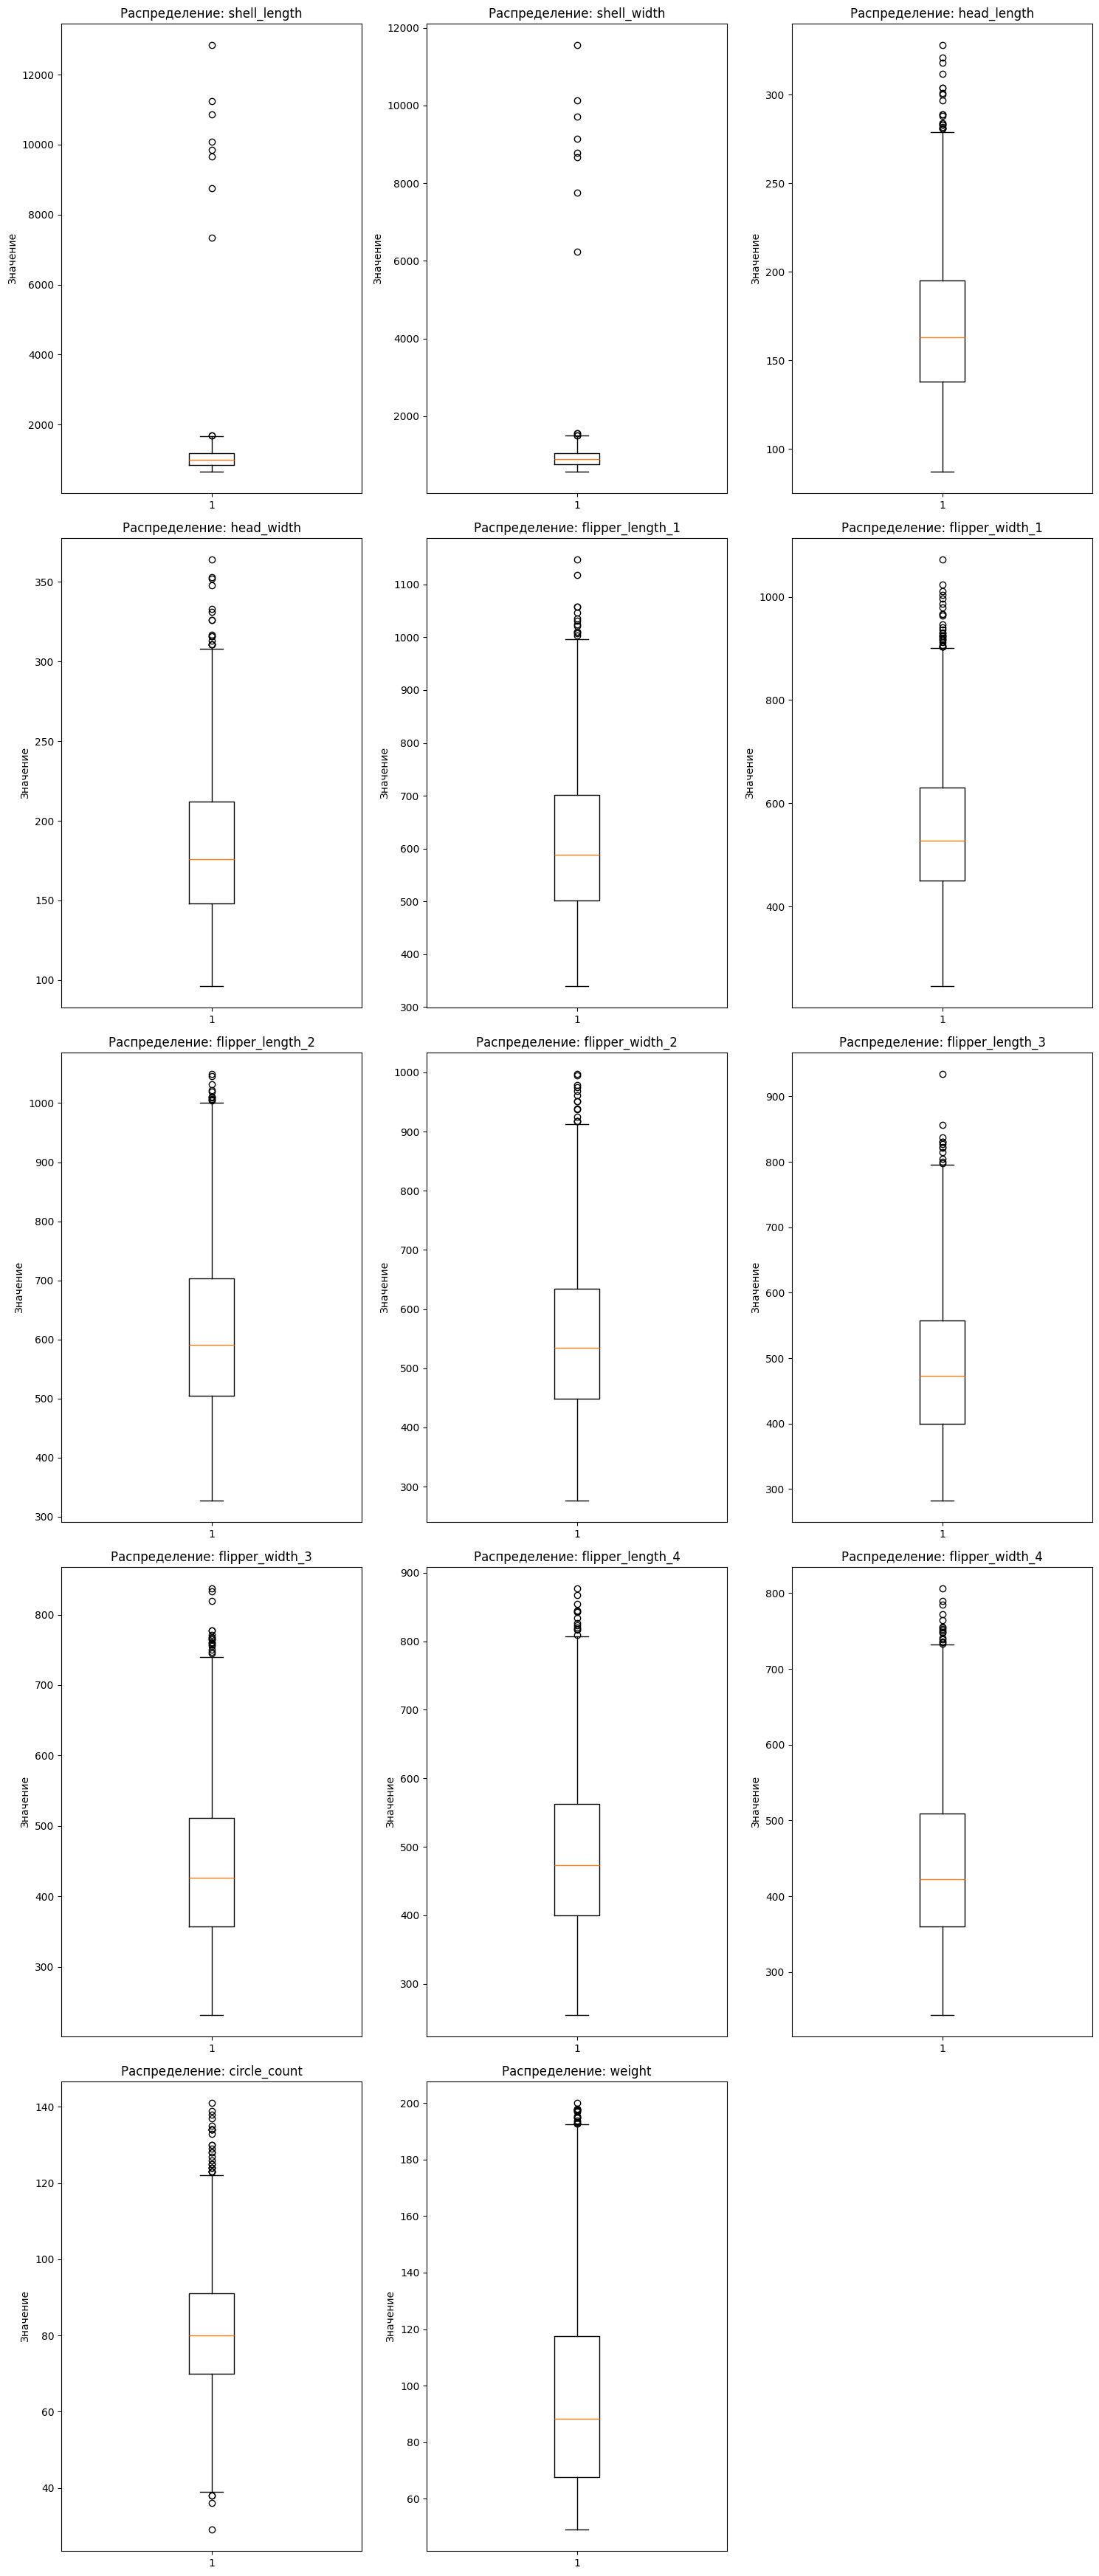

In [17]:
fig, axes = plt.subplots(nrows=5, ncols=3, figsize=(15, 35))

axes = axes.flatten()

for i, column in enumerate(filtered_chelonia_mydas.columns):
    axes[i].boxplot(filtered_chelonia_mydas[column])
    axes[i].set_title(f'Распределение: {column}')
    axes[i].set_ylabel('Значение')

# Удаляем пустой график
fig.delaxes(axes[14])

plt.tight_layout()

plt.show()

На графике распределения данных видно, что `shell_length` и `shell_width` содержат выбросы, что соотвествует информации о умножения некоторых данных на `10`. Сократим эти данные на 10 и снова проверим распределение.

In [18]:
# Функция для возврата столбцов к миллиметрам
def back_to_millimeteres(row):
    # Панцирь зеленой морской черепахи не может достигать размеров более 200 мм
    if row['shell_length'] > 2000: 
        row['shell_length'] = row['shell_length'] / 10
    if row['shell_width'] > 2000:
        row['shell_width'] = row['shell_width'] / 10
    return row  

# Применяем функцию и сохраняем результат в датафрейм
filtered_chelonia_mydas = filtered_chelonia_mydas.apply(back_to_millimeteres, axis=1)

# Проверяем результат 
filtered_chelonia_mydas.describe()

,shell_length,shell_width,head_length,head_width,flipper_length_1,flipper_width_1,flipper_length_2,flipper_width_2,flipper_length_3,flipper_width_3,flipper_length_4,flipper_width_4,circle_count,weight
count,2393.000000,2393.000000,2393.000000,2393.000000,2393.000000,2393.000000,2393.000000,2393.000000,2393.000000,2393.000000,2393.000000,2393.000000,2393.000000,2393.000000
mean,1018.613038,919.001672,169.592144,183.043042,612.060593,549.536147,611.823234,550.681153,487.234434,440.586711,489.392812,441.125784,80.895947,96.172077
std,221.893256,202.043414,41.264553,45.077110,141.837037,131.483959,138.101688,130.791969,110.110794,105.207770,112.267007,104.252285,16.184543,34.844208
min,645.000000,564.000000,87.000000,96.000000,339.000000,245.000000,327.000000,276.000000,282.000000,231.000000,254.000000,243.000000,29.000000,49.045000
25%,837.000000,754.000000,138.000000,148.000000,502.000000,450.000000,505.000000,449.000000,400.000000,357.000000,400.000000,360.000000,70.000000,67.620000
50%,980.000000,889.000000,163.000000,176.000000,588.000000,528.000000,591.000000,534.000000,473.000000,426.000000,473.000000,423.000000,80.000000,88.227000
75%,1167.000000,1054.000000,195.000000,212.000000,702.000000,631.000000,703.000000,635.000000,558.000000,511.000000,563.000000,509.000000,91.000000,117.555000
max,1683.000000,1554.000000,328.000000,364.000000,1147.000000,1072.000000,1049.000000,997.000000,934.000000,837.000000,877.000000,806.000000,141.000000,199.961000


Результаты успешно возвращены к нужным значениям. Можно вернуться к распредлению. 

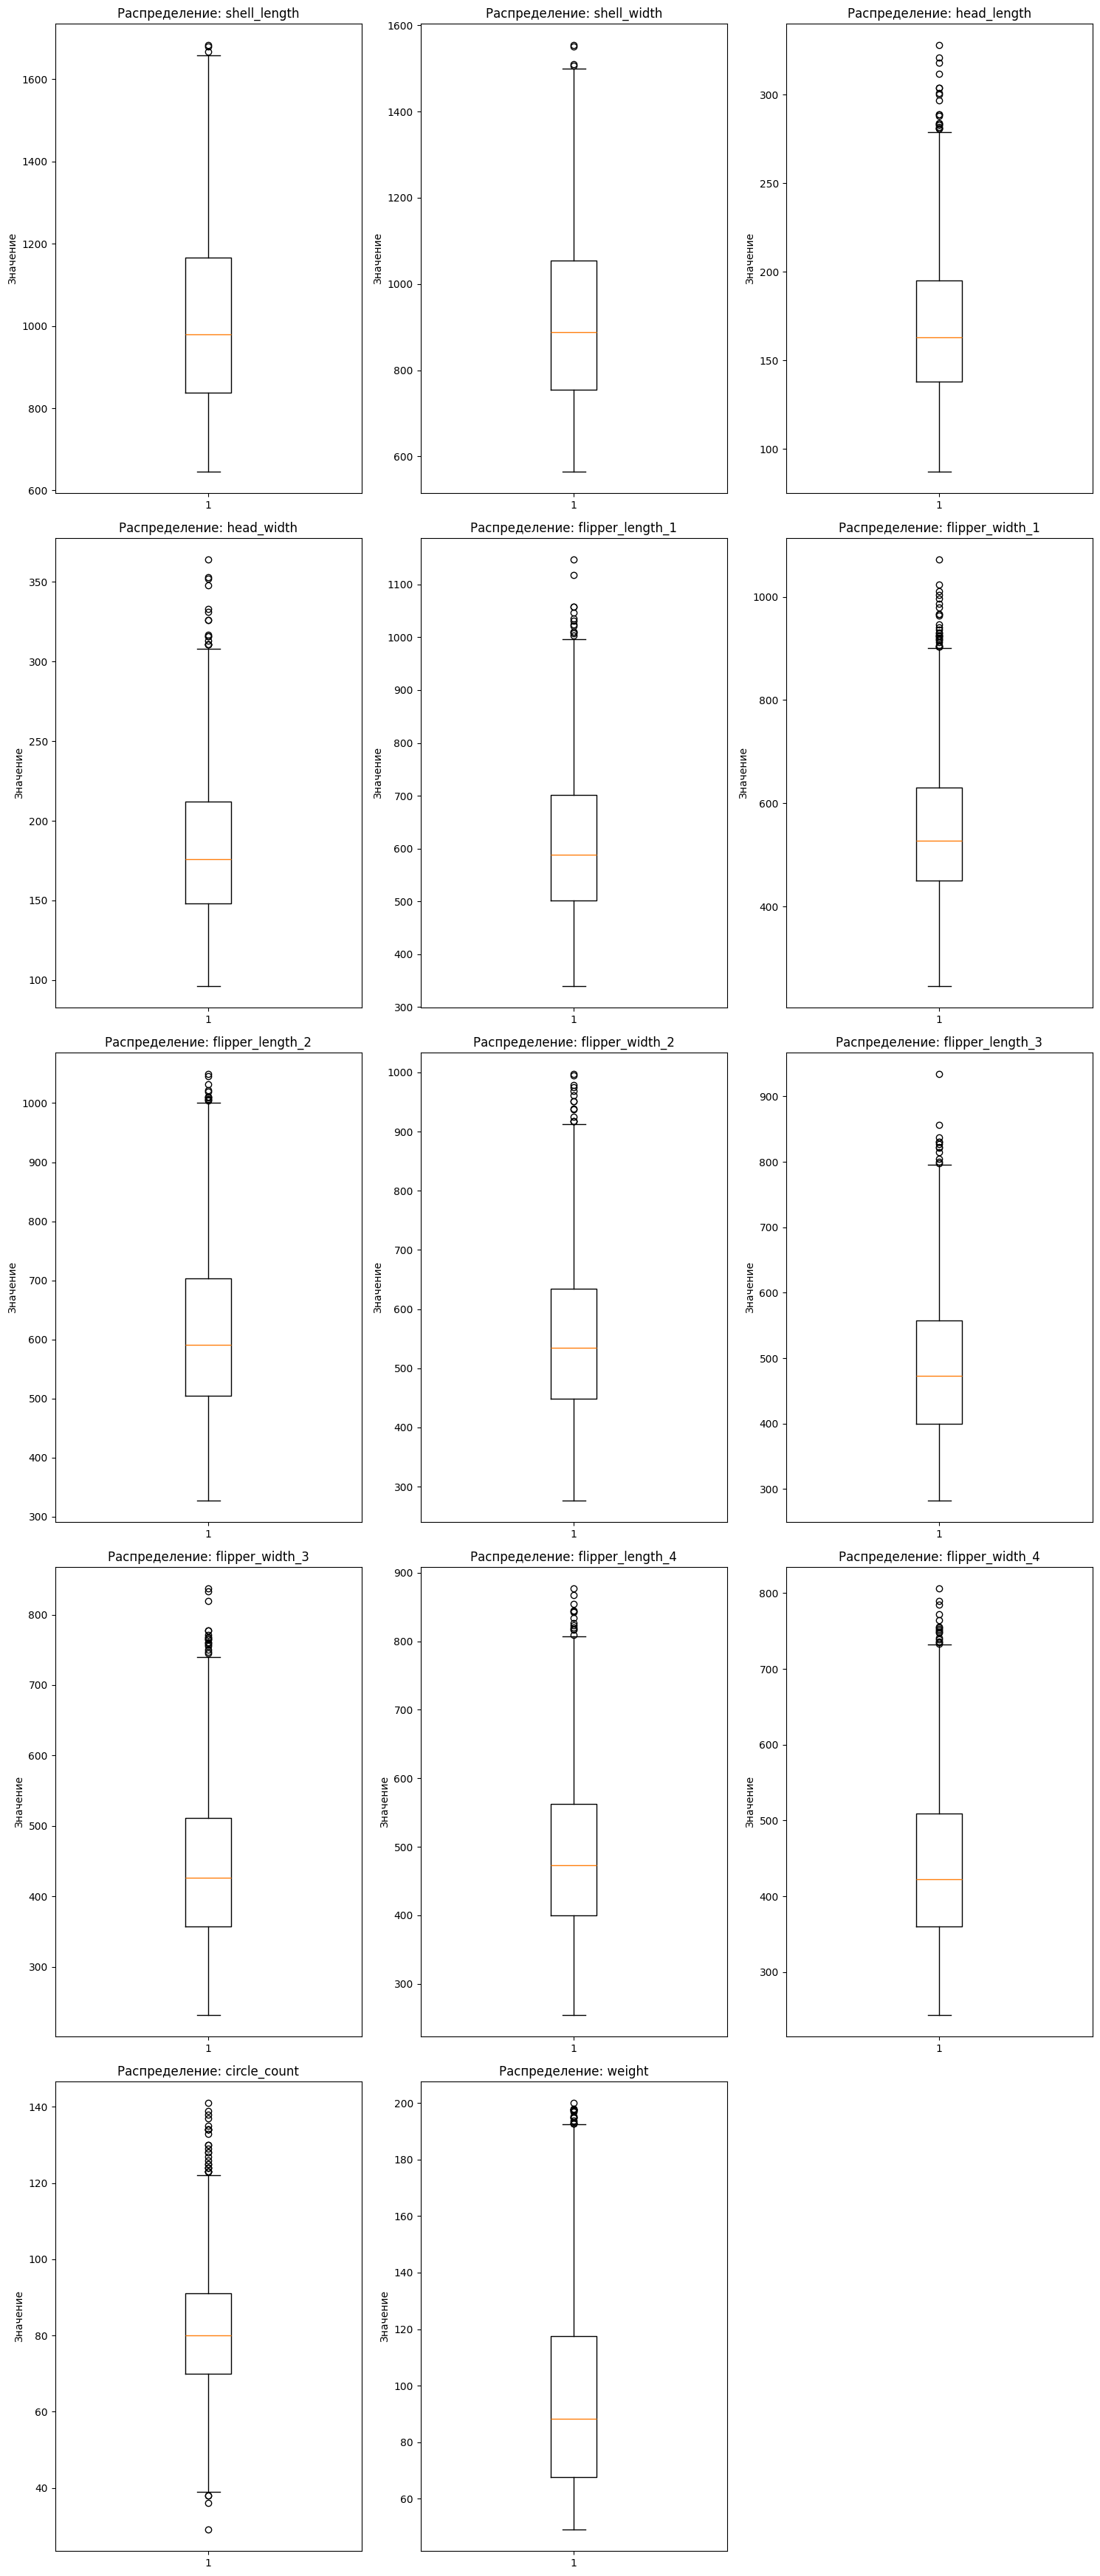

In [19]:
fig, axes = plt.subplots(nrows=5, ncols=3, figsize=(15, 35))

axes = axes.flatten()

for i, column in enumerate(filtered_chelonia_mydas.columns):
    axes[i].boxplot(filtered_chelonia_mydas[column])
    axes[i].set_title(f'Распределение: {column}')
    axes[i].set_ylabel('Значение')

# Удаляем пустой график
fig.delaxes(axes[14])

plt.tight_layout()

plt.show()

Больше в данных не наблюдается больших выбросов, которые могли бы критично повлиять на обучение модели.

---

### 2.9. Исследование масштаба данных

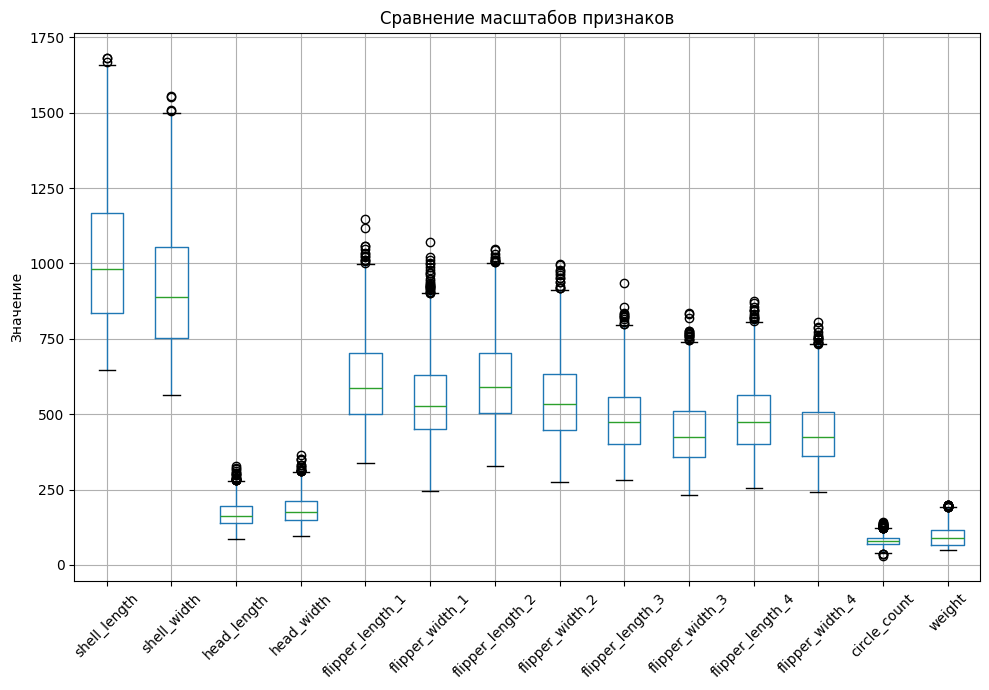

In [20]:
# Строим ящик с усами для каждого из столбцов
plt.figure(figsize=(10, 7))

filtered_chelonia_mydas.boxplot(column=[x for x in filtered_chelonia_mydas.columns], rot=45)

plt.title('Сравнение масштабов признаков')

plt.ylabel('Значение')

plt.tight_layout()

plt.show() 


Большинство данных обладают разным масштабом. Это исказит обучение модели и ухудшит результаты ее предсказаний - следует привести признаки к одному масштабу.

Так как данные содержат выбросы, на этапе предобработки данных будем использовать стандартизацию для масштабирования признаков. 

---

### 2.10. Анализ корреляции между признаками и целевой переменной

In [21]:
# Создаем корреляционную матрицу с признаками
correlation_matrix = filtered_chelonia_mydas[
    filtered_chelonia_mydas.columns
].phik_matrix()

correlation_matrix

interval columns not set, guessing: ['shell_length', 'shell_width', 'head_length', 'head_width', 'flipper_length_1', 'flipper_width_1', 'flipper_length_2', 'flipper_width_2', 'flipper_length_3', 'flipper_width_3', 'flipper_length_4', 'flipper_width_4', 'circle_count', 'weight']


,shell_length,shell_width,head_length,head_width,flipper_length_1,flipper_width_1,flipper_length_2,flipper_width_2,flipper_length_3,flipper_width_3,flipper_length_4,flipper_width_4,circle_count,weight
shell_length,1.000000,0.925573,0.822107,0.817863,0.881482,0.848459,0.871357,0.853388,0.874425,0.851276,0.877267,0.854115,0.514750,0.957915
shell_width,0.925573,1.000000,0.807500,0.791661,0.858676,0.835308,0.858208,0.839471,0.859688,0.828876,0.853532,0.841915,0.501314,0.933920
head_length,0.822107,0.807500,1.000000,0.721679,0.775083,0.762160,0.773381,0.761709,0.783659,0.754141,0.766929,0.756017,0.465332,0.833481
head_width,0.817863,0.791661,0.721679,1.000000,0.763924,0.733931,0.764386,0.754145,0.769102,0.757552,0.781052,0.748891,0.450694,0.827317
flipper_length_1,0.881482,0.858676,0.775083,0.763924,1.000000,0.799325,0.819460,0.809122,0.812898,0.814551,0.811809,0.795858,0.482332,0.887837
flipper_width_1,0.848459,0.835308,0.762160,0.733931,0.799325,1.000000,0.788717,0.791834,0.797343,0.789317,0.790606,0.783807,0.476409,0.858856
flipper_length_2,0.871357,0.858208,0.773381,0.764386,0.819460,0.788717,1.000000,0.796406,0.811865,0.791300,0.808813,0.799366,0.483296,0.881735
flipper_width_2,0.853388,0.839471,0.761709,0.754145,0.809122,0.791834,0.796406,1.000000,0.804494,0.784001,0.813811,0.775026,0.467517,0.863391
flipper_length_3,0.874425,0.859688,0.783659,0.769102,0.812898,0.797343,0.811865,0.804494,1.000000,0.793061,0.817379,0.796612,0.488509,0.879675
flipper_width_3,0.851276,0.828876,0.754141,0.757552,0.814551,0.789317,0.791300,0.784001,0.793061,1.000000,0.795215,0.788957,0.470060,0.860685


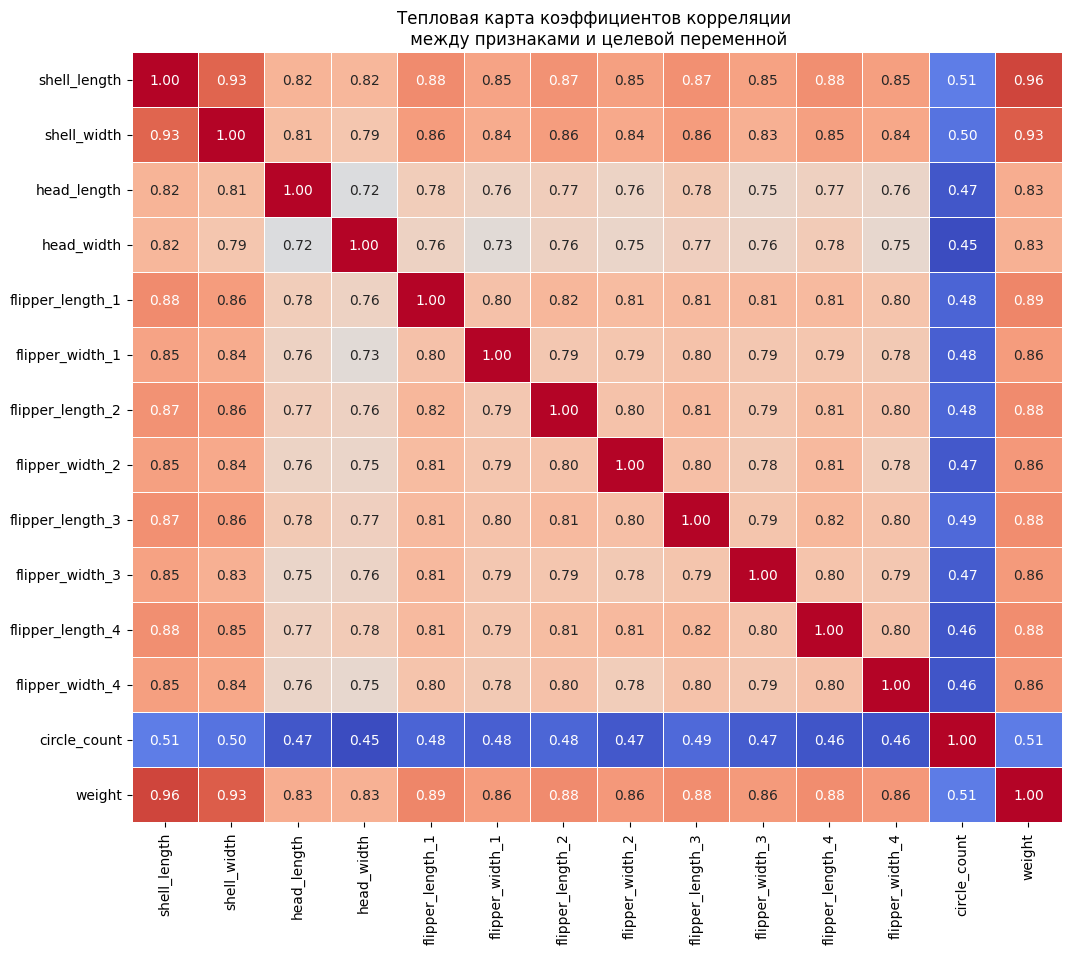

In [22]:
# Для нагладности отобразим на графике

plt.figure(figsize=(12, 10))

sns.heatmap(
    data=correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
    cbar=False
)

plt.title('Тепловая карта коэффициентов корреляции \n между признаками и целевой переменной')
plt.show()

Все признаки имеют довольно сильную корреляцию с весом (`weight`) черепахи, кроме `circle_count`, которая указывает на возраст черепахи, этот признак имеет среднюю корреляцию.

Также, признаки имеют сильную корреляцию между собой в зависимости от замеров определенной части тела. 

Так, `head_length` и `head_width`, `shell_length` и `shell_width`, а также `flipper_length_n` коррелируют между собой. Это вполне логично, ведь лапы черепахи не могут отличаться друг от друга размерами кратно.

Если избавляться от коллинеарности путем удаления признаков, то придется удалить большую часть признаков. Это не выход.

Поэтому нужно попробовать смягчить проблему мультиколлинеарности с помощью регуляризации на этапе обучения моделей.

---

**Микровывод по итогам исследовательского анализа данных**

- Удалено около 16% строк изучаемого вида черепах. Среди этих строк пропуски и дубликаты.
- Обнаружена мультиколлинеарность некоторых признаков. Принято решение не избавляться от нее, потому что признаки занимают значителью часть данных, решение - смягчение проблемы с помощью регуляризации на этапе обучения.
- В данных обнаружены некритичные выбросы. Наилучшим решением будет применить регуляризацию и минимизацию по определенным функциям потерь в ходе обучения.

## 3. Предобработка данных

### 3.1. Разделение данных на выборки

Выборки: обучающая - 60%, валидационная - 20%, тестовая - 20%.

In [23]:
# Отделение признаков и целевой переменной
X = filtered_chelonia_mydas.drop(columns='weight')
y = filtered_chelonia_mydas['weight']

X_train_val, X_test, y_train_val, y_test = train_test_split(X, y,
                                                            test_size=0.2,
                                                            shuffle=True,
                                                            random_state=42)

X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val,
                                                  test_size=0.25,
                                                  shuffle=True,
                                                  random_state=42)


**Распределение данных по выборкам**

Для правильного обучения моделей необходимо убедиться в равности распределения данных по выборкам.

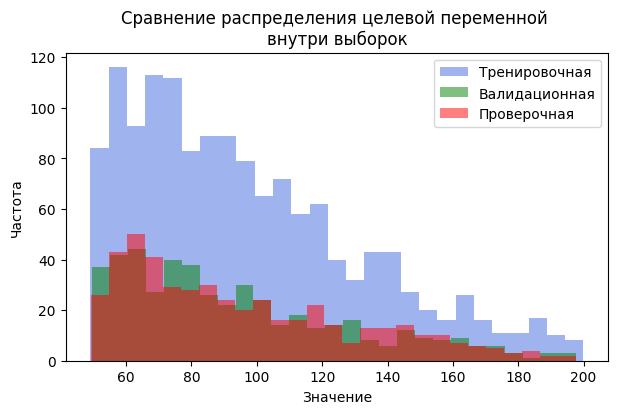

In [24]:
plt.figure(figsize=(7, 4))

plt.hist(y_train, bins=27, alpha=0.5, label='Тренировочная', color='royalblue')
plt.hist(y_val, bins=27, alpha=0.5, label='Валидационная', color='green')
plt.hist(y_test, bins=27, alpha=0.5, label='Проверочная', color='red')

plt.xlabel('Значение')
plt.ylabel('Частота')

plt.title('Сравнение распределения целевой переменной \nвнутри выборок')
plt.legend(loc='upper right')

plt.show()

Данные равномерно распределены по выборкам.

### 3.2. Стандартизация признаков

In [25]:
# Функция для масштабирования данных
def scale_data(X_train, X_val, X_test, method='standard'):
    if method == 'standard':
        mean = X_train.mean()
        std = X_train.std()
        X_train_scaled = (X_train - mean) / std
        X_val_scaled = (X_val - mean) / std
        X_test_scaled = (X_test - mean) / std
    elif method == 'minmax':
        min_val = X_train.min()
        max_val = X_train.max()
        X_train_scaled = (X_train - min_val) / (max_val - min_val)
        X_val_scaled = (X_val - min_val) / (max_val - min_val)
        X_test_scaled = (X_test - min_val) / (max_val - min_val)
    else:
        raise ValueError("Неверный метод масштабирования. Используйте 'standard' или 'minmax'.")
    return X_train_scaled, X_val_scaled, X_test_scaled

# Выборка с стадартизацией
X_train_scaled_std, X_val_scaled_std, X_test_scaled_std = scale_data(X_train, X_val, X_test, 'standard')

# Выборка с нормализацией (для эксперимента)
X_train_scaled_minmax, X_val_scaled_minmax, X_test_scaled_minmax = scale_data(X_train, X_val, X_test, 'minmax')

По итогам масштабирования имеем три выборки: стандартизированную, нормализованную и без масштабирования.

---

## 4. Обучение моделей

### 4.1. Обучение линейных моделей

Будем сравнивать остальные модели с базовой. Если они будут хуже базовой по качеству, при обучении что-то пошло не так. 

Базовая модель будет предсказывать среднее значение целевой переменной из обучающей выборки. В качестве базовой модели используем `DummyRegressor` с параметром `strategy='mean'` (предсказание среднего).

In [26]:
# Обучение DummyRegressor на всех выборках
dummy_notscaled = DummyRegressor(strategy="mean")
dummy_notscaled.fit(X_train, y_train)
y_val_pred_dummy_notscaled = dummy_notscaled.predict(X_val)

dummy_std = DummyRegressor(strategy="mean")
dummy_std.fit(X_train_scaled_std, y_train)
y_val_pred_dummy_std = dummy_std.predict(X_val_scaled_std)

dummy_minmax = DummyRegressor(strategy="mean")
dummy_minmax.fit(X_train_scaled_minmax, y_train)
y_val_pred_dummy_minmax = dummy_minmax.predict(X_val_scaled_minmax)

**Обучение линейной модели**

In [27]:
# Линейная модель без масштабирования
linear_regr_notscaled = LinearRegression()
linear_regr_notscaled.fit(X_train, y_train)
y_val_pred_linear_notscaled = linear_regr_notscaled.predict(X_val)

# Линейная модель с стандартизацией
linear_regr_std = LinearRegression()
linear_regr_std.fit(X_train_scaled_std, y_train)
y_val_pred_linear_std = linear_regr_std.predict(X_val_scaled_std)

# Линейная модель с нормализацией
linear_regr_minmax = LinearRegression()
linear_regr_minmax.fit(X_train_scaled_minmax, y_train)
y_val_pred_linear_minmax = linear_regr_minmax.predict(X_val_scaled_minmax)

**Обучение линейной модели с регуляризацией `Ridge`**

In [28]:
# Подбор оптимального alpha для Ridge
alphas = [0.001, 0.01, 0.1, 1, 10, 100]
best_mae_ridge_notscaled = float('inf')
best_alpha_ridge_notscaled = None
best_ridge_notscaled = None

best_mae_ridge_std = float('inf')
best_alpha_ridge_std = None
best_ridge_std = None

best_mae_ridge_minmax = float('inf')
best_alpha_ridge_minmax = None
best_ridge_minmax = None

for alpha in alphas:
    # Ridge без масштабирования
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train, y_train)
    y_pred = ridge.predict(X_val)
    mae = mean_absolute_error(y_val, y_pred)
    if mae < best_mae_ridge_notscaled:
        best_mae_ridge_notscaled = mae
        best_alpha_ridge_notscaled = alpha
        best_ridge_notscaled = ridge

    # Ridge со стандартизацией
    ridge_std = Ridge(alpha=alpha)
    ridge_std.fit(X_train_scaled_std, y_train)
    y_pred_std = ridge_std.predict(X_val_scaled_std)
    mae_std = mean_absolute_error(y_val, y_pred_std)
    if mae_std < best_mae_ridge_std:
        best_mae_ridge_std = mae_std
        best_alpha_ridge_std = alpha
        best_ridge_std = ridge_std

    # Ridge с нормализацией
    ridge_minmax = Ridge(alpha=alpha)
    ridge_minmax.fit(X_train_scaled_minmax, y_train)
    y_pred_minmax = ridge_minmax.predict(X_val_scaled_minmax)
    mae_minmax = mean_absolute_error(y_val, y_pred_minmax)
    if mae_minmax < best_mae_ridge_minmax:
        best_mae_ridge_minmax = mae_minmax
        best_alpha_ridge_minmax = alpha
        best_ridge_minmax = ridge_minmax

print(f"Лучший alpha для Ridge (без масштабирования): {best_alpha_ridge_notscaled}")
print(f"Лучший alpha для Ridge (стандартизация): {best_alpha_ridge_std}")
print(f"Лучший alpha для Ridge (нормализация): {best_alpha_ridge_minmax}")

# Предсказания Ridge с лучшими alpha
y_val_pred_ridge_notscaled = best_ridge_notscaled.predict(X_val)
y_val_pred_ridge_std = best_ridge_std.predict(X_val_scaled_std)
y_val_pred_ridge_minmax = best_ridge_minmax.predict(X_val_scaled_minmax)

Лучший alpha для Ridge (без масштабирования): 100
Лучший alpha для Ridge (стандартизация): 10
Лучший alpha для Ridge (нормализация): 0.1


**Обучение линейной модели с регуляризацией `Lasso`**

In [29]:
# Подбор оптимального alpha для Lasso
best_mae_lasso_notscaled = float('inf')
best_alpha_lasso_notscaled = None
best_lasso_notscaled = None

best_mae_lasso_std = float('inf')
best_alpha_lasso_std = None
best_lasso_std = None

best_mae_lasso_minmax = float('inf')
best_alpha_lasso_minmax = None
best_lasso_minmax = None

for alpha in alphas:
    # Lasso без масштабирования
    lasso = Lasso(alpha=alpha)
    lasso.fit(X_train, y_train)
    y_pred = lasso.predict(X_val)
    mae = mean_absolute_error(y_val, y_pred)
    if mae < best_mae_lasso_notscaled:
        best_mae_lasso_notscaled = mae
        best_alpha_lasso_notscaled = alpha
        best_lasso_notscaled = lasso

    # Lasso со стандартизацией
    lasso_std = Lasso(alpha=alpha)
    lasso_std.fit(X_train_scaled_std, y_train)
    y_pred_std = lasso_std.predict(X_val_scaled_std)
    mae_std = mean_absolute_error(y_val, y_pred_std)
    if mae_std < best_mae_lasso_std:
        best_mae_lasso_std = mae_std
        best_alpha_lasso_std = alpha
        best_lasso_std = lasso_std

    # Lasso с нормализацией
    lasso_minmax = Lasso(alpha=alpha)
    lasso_minmax.fit(X_train_scaled_minmax, y_train)
    y_pred_minmax = lasso_minmax.predict(X_val_scaled_minmax)
    mae_minmax = mean_absolute_error(y_val, y_pred_minmax)
    if mae_minmax < best_mae_lasso_minmax:
        best_mae_lasso_minmax = mae_minmax
        best_alpha_lasso_minmax = alpha
        best_lasso_minmax = lasso_minmax

print(f"Лучший alpha для Lasso (без масштабирования): {best_alpha_lasso_notscaled}")
print(f"Лучший alpha для Lasso (стандартизация): {best_alpha_lasso_std}")
print(f"Лучший alpha для Lasso (нормализация): {best_alpha_lasso_minmax}")

# Предсказания Lasso с лучшими alpha
y_val_pred_lasso_notscaled = best_lasso_notscaled.predict(X_val)
y_val_pred_lasso_std = best_lasso_std.predict(X_val_scaled_std)
y_val_pred_lasso_minmax = best_lasso_minmax.predict(X_val_scaled_minmax)

Лучший alpha для Lasso (без масштабирования): 10
Лучший alpha для Lasso (стандартизация): 1
Лучший alpha для Lasso (нормализация): 0.01


**Обучение линейной модели с помощью градиентного спуска и гиперпараметрами**

In [30]:

# Подбор оптимального penalty для SGDRegressor
penalties = ['l1', 'l2']
alphas_sgd = [0.01, 0.1, 1, 10, 100]
losses = ['squared_error', 'huber']
learning_rates = ['constant', 'invscaling', 'adaptive']
eta0s = [0.001, 0.01, 0.1]

best_mae_sgd_notscaled = float('inf')
best_params_sgd_notscaled = None
best_sgd_notscaled = None

best_mae_sgd_std = float('inf')
best_params_sgd_std = None
best_sgd_std = None

best_mae_sgd_minmax = float('inf')
best_params_sgd_minmax = None
best_sgd_minmax = None

for penalty in penalties:
    for alpha in alphas_sgd:
        for loss in losses:
            for eta0 in eta0s:
                for learning_rate in learning_rates:
                    # SGDRegressor без масштабирования
                    sgd = SGDRegressor(penalty=penalty, loss=loss, alpha=alpha, eta0=eta0, learning_rate=learning_rate, max_iter=2500, random_state=42)
                    sgd.fit(X_train, y_train)
                    y_pred = sgd.predict(X_val)
                    mae = mean_absolute_error(y_val, y_pred)
                    if mae < best_mae_sgd_notscaled:
                        best_mae_sgd_notscaled = mae
                        best_params_sgd_notscaled = (penalty, loss, alpha, eta0, learning_rate)
                        best_sgd_notscaled = sgd

                    # SGDRegressor со стандартизацией
                    sgd_std = SGDRegressor(penalty=penalty, loss=loss, alpha=alpha, eta0=eta0, learning_rate=learning_rate, max_iter=2500, random_state=42)
                    sgd_std.fit(X_train_scaled_std, y_train)
                    y_pred_std = sgd_std.predict(X_val_scaled_std)
                    mae_std = mean_absolute_error(y_val, y_pred_std)
                    if mae_std < best_mae_sgd_std:
                        best_mae_sgd_std = mae_std
                        best_params_sgd_std = (penalty, loss, alpha, eta0, learning_rate)
                        best_sgd_std = sgd_std

                    # SGDRegressor с нормализацией
                    sgd_minmax = SGDRegressor(penalty=penalty, loss=loss, alpha=alpha, eta0=eta0, learning_rate=learning_rate, max_iter=2500, random_state=42)
                    sgd_minmax.fit(X_train_scaled_minmax, y_train)
                    y_pred_minmax = sgd_minmax.predict(X_val_scaled_minmax)
                    mae_minmax = mean_absolute_error(y_val, y_pred_minmax)
                    if mae_minmax < best_mae_sgd_minmax:
                        best_mae_sgd_minmax = mae_minmax
                        best_params_sgd_minmax = (penalty, loss, alpha, eta0, learning_rate)
                        best_sgd_minmax = sgd_minmax

print(f"Лучшие параметры для SGDRegressor (без масштабирования): {best_params_sgd_notscaled}")
print(f"Лучшие параметры для SGDRegressor (стандартизация): {best_params_sgd_std}")
print(f"Лучшие параметры для SGDRegressor (нормализация): {best_params_sgd_minmax}")

# Предсказания SGDRegressor с лучшими параметрами
y_val_pred_sgd_notscaled = best_sgd_notscaled.predict(X_val)
y_val_pred_sgd_std = best_sgd_std.predict(X_val_scaled_std)
y_val_pred_sgd_minmax = best_sgd_minmax.predict(X_val_scaled_minmax)


Лучшие параметры для SGDRegressor (без масштабирования): ('l2', 'huber', 0.1, 0.01, 'adaptive')
Лучшие параметры для SGDRegressor (стандартизация): ('l1', 'squared_error', 1, 0.001, 'constant')
Лучшие параметры для SGDRegressor (нормализация): ('l1', 'squared_error', 0.1, 0.1, 'invscaling')


### 4.2. Формирование итоговой таблицы с результатами моделей

In [31]:

# Функция для расчета всех метрик
def calculate_all_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred)
    return {
        'MAE': round(mae, 4),
        'MSE': round(mse, 4),
        'R2': round(r2, 4),
        'MAPE': round(mape * 100, 2)
    }

# Сбор результатов всех моделей
results = []

# DummyRegressor
results.append({'Model': 'Dummy', 'Dataset': 'Not Scaled', **calculate_all_metrics(y_val, y_val_pred_dummy_notscaled)})
results.append({'Model': 'Dummy', 'Dataset': 'Standard', **calculate_all_metrics(y_val, y_val_pred_dummy_std)})
results.append({'Model': 'Dummy', 'Dataset': 'MinMax', **calculate_all_metrics(y_val, y_val_pred_dummy_minmax)})

# LinearRegression
results.append({'Model': 'LinearRegression', 'Dataset': 'Not Scaled', **calculate_all_metrics(y_val, y_val_pred_linear_notscaled)})
results.append({'Model': 'LinearRegression', 'Dataset': 'Standard', **calculate_all_metrics(y_val, y_val_pred_linear_std)})
results.append({'Model': 'LinearRegression', 'Dataset': 'MinMax', **calculate_all_metrics(y_val, y_val_pred_linear_minmax)})

# Ridge
results.append({'Model': 'Ridge', 'Dataset': 'Not Scaled', **calculate_all_metrics(y_val, y_val_pred_ridge_notscaled)})
results.append({'Model': 'Ridge', 'Dataset': 'Standard', **calculate_all_metrics(y_val, y_val_pred_ridge_std)})
results.append({'Model': 'Ridge', 'Dataset': 'MinMax', **calculate_all_metrics(y_val, y_val_pred_ridge_minmax)})

# Lasso
results.append({'Model': 'Lasso', 'Dataset': 'Not Scaled', **calculate_all_metrics(y_val, y_val_pred_lasso_notscaled)})
results.append({'Model': 'Lasso', 'Dataset': 'Standard', **calculate_all_metrics(y_val, y_val_pred_lasso_std)})
results.append({'Model': 'Lasso', 'Dataset': 'MinMax', **calculate_all_metrics(y_val, y_val_pred_lasso_minmax)})

# SGDRegressor
results.append({'Model': 'SGDRegressor', 'Dataset': 'Not Scaled', **calculate_all_metrics(y_val, y_val_pred_sgd_notscaled)})
results.append({'Model': 'SGDRegressor', 'Dataset': 'Standard', **calculate_all_metrics(y_val, y_val_pred_sgd_std)})
results.append({'Model': 'SGDRegressor', 'Dataset': 'MinMax', **calculate_all_metrics(y_val, y_val_pred_sgd_minmax)})

# Создание DataFrame с результатами
pd.set_option('display.float_format', '{:.4f}'.format)
results_df = pd.DataFrame(results)
display(results_df.sort_values(by='MAE', ascending=True))

,Model,Dataset,MAE,MSE,R2,MAPE
13,SGDRegressor,Standard,3.2274,19.8726,0.9832,3.4600
14,SGDRegressor,MinMax,3.2481,18.9553,0.9840,3.5800
10,Lasso,Standard,3.2692,20.0795,0.9831,3.5300
9,Lasso,Not Scaled,3.3165,19.3079,0.9837,3.7400
11,Lasso,MinMax,3.3289,19.3512,0.9837,3.7600
7,Ridge,Standard,3.3321,19.3570,0.9837,3.7600
8,Ridge,MinMax,3.3365,19.3631,0.9837,3.7700
3,LinearRegression,Not Scaled,3.3404,19.3994,0.9836,3.7800
4,LinearRegression,Standard,3.3404,19.3994,0.9836,3.7800
5,LinearRegression,MinMax,3.3404,19.3994,0.9836,3.7800


Все модели хорошо обучены и справляются лучше базовой. Подробный анализ результатов приведен в следующем разделе.

---

## 5. Сравнение моделей на валидационной выборке

### 5.1. Сравнение моделей

Каждая из моделей существенно улучшила результаты по сравнению с базовой моделью. Все модели кроме базовой и `SGDRegressor` на немасштабированных данных борются за десятые доли ошибки.

Модель `SGDRegressor` показывает худшие результаты из-за плохой адаптации к немасштабированным данным. Такие данные не позволяют правильно настроить веса из-за разности измерения своих признаков и, соответственно, из-за разности общего распределения признаков.

Остальные данные также обучались на немасштабированных данных, но показали более хорошие результаты. Секрет кроется в использовании моделью `SGDRegressor` градиентного спуска, который крайне капризен к масштабу данных. 

### 5.2. Лучшая модель на валидационной выборке

По основному параметру `MAE` лучшая модель на валидационной выборке - `SGDRegressor` с стандартизированными данными со параметрами `penalty='l1'`, `loss='squared_error'`, `aplha=1`, `eta0=0.001`, `learning_rate='constant'`. 

Значение параметра `MAE` для этой модели составило `3.2274`, что укладывается в критерии заказчика - не более 5 кг. 

### 5.3. Лучшая по качеству модель

Работу продолжим с моделью `SGDRegressor`, обученный на стандартизированных данных. Выбор объясняется так:
- Модель показывает лучшие результаты на критерии важном для заказчика. Помимо прочего модель показывает лучшие результаты по всем метрикам за исключением `MSE`, где лидирует `SGDRegressor`, обученный на нормализованной выборке, однако, разница небольшая.
- Работа с волонтерами повышает риск ошибки и выбросов - при получении данных в реальном времени стандартизирование признаков позволит сгладить ошибку выброса.
- Размер данных позволяет использовать небольшой шаг `eta0=0.001` и не сильно замедляет процесс обучения. Однако, при увеличении количества данных в несколько раз для обучения, необходимо повысить шаг или выбрать другую модель, чтобы процесс не затянулся.

---

## 6. Проверка лучшей модели на тестовой выборке

### 6.1. Проверка метрик лучшей модели на тестовой выборке

In [32]:
# Предсказания лучшей модели на тестовой выборке
y_test_pred = best_sgd_std.predict(X_test_scaled_std)

calculate_all_metrics(y_test, y_test_pred)

{'MAE': 3.564, 'MSE': 22.1806, 'R2': 0.9819, 'MAPE': 3.83}

### 6.2. Исследование наличия признаков переобучения модели

In [33]:
# Предсказания для обучающей выборки
y_train_pred = best_sgd_std.predict(X_train_scaled_std)
print('Показатели модели на обучающей выборке: ', calculate_all_metrics(y_train, y_train_pred))
print('Показатели модели на валидационной выборке: ', calculate_all_metrics(y_val, y_val_pred_sgd_std))
print('Показатели модели на тестовой выборке', calculate_all_metrics(y_test, y_test_pred))

Показатели модели на обучающей выборке:  {'MAE': 3.6715, 'MSE': 23.3324, 'R2': 0.9808, 'MAPE': 3.82}
Показатели модели на валидационной выборке:  {'MAE': 3.2274, 'MSE': 19.8726, 'R2': 0.9832, 'MAPE': 3.46}
Показатели модели на тестовой выборке {'MAE': 3.564, 'MSE': 22.1806, 'R2': 0.9819, 'MAPE': 3.83}


Признаков переобучения не обнаружено: модель показывает хорошие результаты на всех метриках, независимо от данных.

### 6.3. Рекомендация к внедрению

Модель можно **рекомендовать** к внедрению:
- Модель полностью соответствует требованиям заказчика
- Модель не показывает признаков переобучения
- Модель показывает лучшие результаты по сравнению с остальными моделями

---

## 7. Оценка важности признаков

In [34]:
best_sgd_std.coef_

array([12.89403472,  6.62103955,  1.29865935,  0.86114399,  2.43105211,
        1.32196394,  1.76935449,  1.41684877,  2.00144348,  1.25051957,
        1.71144946,  1.41159764,  0.        ])

Наиболее важными признаками для модели стали `shell_length` и `shell_width`. Это вполне закономерно: наибольший вес будет иметь черепаха с наибольшим панцирем. Габариты частей тела получили меньшие коэффициенты, потому что части тела если и растут, то прибавляют меньше киллограмм к общему весу.

Наименьшим по важности признаком оказался `circles_count`, который указывает на возраст черепахи. Признак получил коэффициент `0`, то есть он не участвует в оценке вообще. Габариты черепахи после взросления не меняются в зависимости от возраста, различие есть только между молодыми и взрослыми особями. 

`circles_count` также получил наименьший коэффициент корреляции с весом по результатам корреляционного анализа. Логично, что и модель захотела исключить признак по сравнению с другими.

---

## 8. Функция для прогнозирования веса черепахи

In [35]:
# Выводим коэффициенты лучшей модели, чтобы использовать их как константы
COEFS = best_sgd_std.coef_
INTERCEPT = best_sgd_std.intercept_

display(COEFS, INTERCEPT)

array([12.89403472,  6.62103955,  1.29865935,  0.86114399,  2.43105211,
        1.32196394,  1.76935449,  1.41684877,  2.00144348,  1.25051957,
        1.71144946,  1.41159764,  0.        ])

array([97.15096438])

In [36]:
# Функция принимает отфильтрованную строку с признаками черепахи, среднее и стандартное отклоение каждой строки, отсутп и коэффициенты
def predict_turtle_weight(turtle, turtle_mean, turtle_std, intercept, coefs):
    # Стандартизируем значения признаков
    turtle_scaled = (turtle - turtle_mean) / turtle_std

    # Считаем предсказание
    predicted_weight = intercept + (coefs * turtle_scaled).sum()
    
    return predicted_weight

# --- ПРИМЕР ПРИМЕНЕНИЯ ФУНКЦИИ ---

# Датафрейм должен иметь 13 выбранных нами признаков
weight = filtered_chelonia_mydas.pop('weight').to_frame()

turtles_std = filtered_chelonia_mydas.std()
turtles_mean = filtered_chelonia_mydas.mean()

# Формируем датафрейм для сравнения настоящего веса и предсказанного для примера
weight['predicted_weight'] = filtered_chelonia_mydas.apply(predict_turtle_weight,
                                                                            axis=1,
                                                                            args=[turtles_mean, turtles_std, INTERCEPT[0], COEFS])
# Демонстрация результата
weight.head()


,weight,predicted_weight
8,56.3520,55.3446
11,154.0740,148.9119
16,87.6950,94.8200
21,92.7070,94.7328
23,75.8290,77.9333


Функция успешно составлена и протестирована.

---

## 9. Общие выводы и рекомендации по дальнейшей работе

В ходе поиска наилучшей модели для поставленной задачи изучены: `LinearRegressor`, `Ridge`, `Lasso` и `SGDRegressor`.

Каждая модель на 3-х разных выборках: немасштабированной, нормализованной и стандартизированной. Также для каждой модели подбирались наиболее эффективные гиперпараметры, позволяющие увеличить достоверность предсказания на основной метрике `MAE` и дополнительных метриках `MSE`, `MAPE` и `R2`.

Исследование показало: наилучшая модель для поставленной задачи - `SGDRegressor`, обученная на стандартизированной выборке, с регуляризацией `L1` или `Lasso`, минимизацией функции потерь `squered_error` (`MSE` или средняя квадратичная ошибка), значением силы регуляризации `1` и постоянным шагом обучения `0.001`.
У архитектуры следующие показатели метрик: `MAE` - 3.2274, `MSE` - 19.8726, `R2` - 0.9832, `MAPE` - 3.46%.

Итоговая модель рекомендуется к внедрению, так как:
- Модель показывает лучшие результаты на критерии важном для заказчика. Помимо прочего модель показывает лучшие результаты по дополнительным метрикам.
- Используемые гиперпараметры и стандартизированная выборка помогают сгладить ошибки выбросов при работе модели в реальном времени.

Наиболее важным признаком для модели оказался размер панциря черепахи, вторые по степени важности габариты конечностей, круги на панцире, указывающие на возраст черепахи, оказались неважны модели для предсказания результата.

Подобранная модель хорошо справится с обучением для предсказания массы других видов черепах. Однако, нужно иметь в виду следующие ограничения:
- Нынешний небольшой набор данных позволяет использовать небольшой шаг равный `0.001` и не замедлять процесс обучения. При использовании набора данных, кратно большего по величине, рекомендуется снизить шаг при слишком долгом обучении модели.
- Модель должна хорошо справляться с выбросами засчет стандартизации данных и подобранных гиперпараметров. Если возникнет потребность заменить модель, например, на вторую по качеству предсказания метрик (`SGDRegressor`, обученная на нормализованных данных и другими гиперпараметрами), преимущества нынешней модели не сохранятся и придется проводить повторное исследование.

Для дальнейшего развития проекта можно подумать над автоматизацией процесса сбора данных. В ходе выполнения исследования были обнаружены явные ошибки, допущенные волонтером при сборе данных.

Помимо прочего, часть данных о габаритах конечностей черепах отсутствует в виду возможной технической ошибки. 
